<a href="https://colab.research.google.com/github/juniorsiolo-ux/PROYECTO2/blob/main/01_ACA1_ETL_EDA_Aromaclean.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aromaclean · ACA 1 · Preparación de la ejecución y ajuste metodológico
**Proyecto de Grado II · Especialización en Analítica de Datos · CUN**

Cuaderno de ETL y EDA multivariado del **objetivo específico 1**: *evaluar el comportamiento y las preferencias de las consumidoras potenciales de jabones artesanales en Duitama mediante estadística descriptiva*.

**Cómo ejecutarlo en Google Colab:** clona el repositorio (`!git clone <URL_DEL_REPOSITORIO>`), entra a la carpeta con `%cd` y ejecuta *Entorno → Ejecutar todo*. Si no clonas el repositorio, el cuaderno te pedirá subir el CSV de `data/raw/`. El cuaderno lee `data/raw/` y escribe en `data/processed/` y `outputs/`. Semilla fija: `SEED = 42`.

**Contenido:** 1) Configuración · 2) Adquisición y ficha del dataset · 3) Diccionario de datos · 4) ETL con conteos antes/después · 5) Comparación de alternativas de limpieza · 6) EDA univariado · 7) EDA multivariado (Pearson, Spearman, chi-cuadrado, VIF, desbalance, fechas) · 8) Robustez por subgrupos · 9) KPIs del enfoque descriptivo · 10) Hallazgos y decisiones · 11) Protocolo de evaluación en código · 12) Exportación.

## 1. Configuración

In [ ]:
import json, random, platform, warnings, sys
if "google.colab" in sys.modules:
    !pip -q install statsmodels openpyxl
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)
rng = np.random.default_rng(SEED)

# Raíz del repositorio (funciona si el cuaderno se ejecuta desde la raíz o desde /notebooks)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_XLSX = ROOT / "data/raw/RESPUESTAS_TRABAJO_DE_GRADO.xlsx"
RAW_CSV  = ROOT / "data/raw/respuestas_encuesta_aromaclean_2025-02.csv"
HOJA = "Respuestas de formulario 1"
PROC = ROOT / "data/processed"; FIG = ROOT / "outputs/figures"; TAB = ROOT / "outputs/tables"
for p in (PROC, FIG, TAB): p.mkdir(parents=True, exist_ok=True)

# Fecha en que el equipo obtuvo la copia de la base (se registra en la ficha del dataset)
FECHA_OBTENCION = "2026-10-25"
# El archivo depurado no tiene marca temporal; el periodo viene del formulario original de Google Forms
PERIODO = "17 a 19 de febrero de 2025 (marca temporal del formulario original; el archivo depurado no la incluye)"
# Decisión sobre duplicados exactos (ver sección 5): False = conservarlos
ELIMINAR_DUPLICADOS = False

sns.set_theme(style="whitegrid", context="notebook")
VERDE, VERDE_CL, GRIS, ACENTO = "#2F6B4F", "#9CC5A8", "#8A8F94", "#C8793A"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "axes.titleweight": "bold",
                     "axes.titlesize": 11, "axes.labelsize": 10})
RES = {}   # resultados clave que luego se citan en el documento (ninguna cifra se escribe a mano)

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG / name, bbox_inches="tight"); plt.show()

def wilson(k, n, alpha=0.05):
    lo, hi = proportion_confint(k, n, alpha=alpha, method="wilson"); return lo, hi

print("Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__)

Python 3.13.16 | pandas 2.2.3 | numpy 2.1.3


## 2. Adquisición de los datos y ficha del dataset

In [ ]:
# 1) Excel original (hoja de respuestas de Google Forms). En Colab, si no está en el repositorio, se sube con un botón.
if not RAW_XLSX.exists() and not RAW_CSV.exists():
    try:
        from google.colab import files
        print("Sube el archivo RESPUESTAS_TRABAJO_DE_GRADO.xlsx")
        up = files.upload(); name = next(iter(up))
        RAW_XLSX.parent.mkdir(parents=True, exist_ok=True); Path(name).replace(RAW_XLSX)
    except ImportError:
        raise FileNotFoundError("Coloca el Excel en data/raw/")
if RAW_XLSX.exists():
    raw = pd.read_excel(RAW_XLSX, sheet_name=HOJA)          # fuente principal: el Excel
    raw.to_csv(RAW_CSV, index=False, encoding="utf-8-sig")   # copia cruda en CSV para trazabilidad
else:
    raw = pd.read_csv(RAW_CSV, encoding="utf-8-sig")
COLS14 = ["edad", "estrato", "frec_limpieza", "tipo_producto", "factores_compra",
        "uso_previo_artesanal", "frec_compra", "presentacion", "canal", "precio",
        "pagar_mas", "motivadores", "interes_probar", "prob_compra"]
assert raw.shape[1] == len(COLS14), "El Excel debe tener las 14 preguntas de la encuesta"
raw.columns = COLS14
df0 = raw.copy()                      # copia intacta (14 columnas) para los conteos "antes"
raw.insert(0, "id", range(1, len(raw) + 1))   # el archivo depurado no trae identificador: se genera uno consecutivo
COLS = ["id"] + COLS14
print(raw.shape); raw.head(3)

Sube el archivo RESPUESTAS_TRABAJO_DE_GRADO.xlsx


Saving RESPUESTAS TRABAJO DE GRADO.xlsx to RESPUESTAS TRABAJO DE GRADO.xlsx
(374, 15)


,id,edad,estrato,frec_limpieza,tipo_producto,factores_compra,uso_previo_artesanal,frec_compra,presentacion,canal,precio,pagar_mas,motivadores,interes_probar,prob_compra
0,1,40 - 50 años,Estrato 4,Ocasionalmente,Jabón líquido,"Ingredientes naturales, Beneficios específicos...",Si,Cada 2-3 meses,Líquido,Venta en línea,$10.000 - $12.000,Sí,"Uso de ingredientes naturales, Compromiso con ...",Si,3
1,2,20 - 30 años,Estrato 3,Varias veces al día,"Jabón líquido, Espumas limpiadoras","Marca reconocida, Beneficios específicos para ...",Si,Cada 2-3 meses,Barra sólida,Venta en línea,$7.000 - $9.000,Sí,"Beneficios para la piel, Compromiso con el med...",Si,5
2,3,40 - 50 años,Estrato 2,2 - 3 veces a la semana,Jabón en barra,"Precio, Beneficios específicos para la piel, P...",Si,Cada 2-3 meses,Barra sólida,Tiendas especializadas en cosmética,$7.000 - $9.000,Sí,"Beneficios para la piel, Compromiso con el med...",Si,2


In [ ]:
ficha = pd.DataFrame({
    "Elemento": ["Fuente", "Enlace / ubicación", "Licencia o autorización", "Fecha de obtención de la copia",
                 "Periodo cubierto (respuestas)", "Registros", "Variables", "Variable objetivo",
                 "Unidad de análisis", "Datos personales"],
    "Descripción": [
        "Encuesta estructurada (Google Forms) aplicada a mujeres de 20 a 50 años de Duitama, Boyacá, en el trabajo de grado de pregrado de D. L. Camargo Fuquen (2025, UIS), integrante de este equipo.",
        "data/raw/RESPUESTAS_TRABAJO_DE_GRADO.xlsx (hoja 'Respuestas de formulario 1') y copia en CSV; repositorio GitHub del proyecto.",
        "Autorización de la autora de la base (ver docs/autorizacion_uso_datos.md) y consentimiento de las participantes: el encabezado de la encuesta declara uso exclusivo académico e investigativo.",
        FECHA_OBTENCION,
        PERIODO,
        f"{len(raw):,}".replace(",", "."),
        "14 preguntas (se genera además un identificador consecutivo, id)",
        "intencion_alta = 1 si la probabilidad de compra (pregunta 14, escala 1–5) es 4 o 5; en caso contrario 0. Se conserva también prob_compra (1–5).",
        "Cada respuesta de formulario = una mujer encuestada",
        "No contiene nombres, documentos, correos ni teléfonos. Solo 14 respuestas cerradas; el archivo depurado no incluye marca temporal."]})
ficha.to_csv(TAB / "ficha_dataset.csv", index=False, encoding="utf-8-sig")
ficha

,Elemento,Descripción
0,Fuente,Encuesta estructurada (Google Forms) aplicada ...
1,Enlace / ubicación,data/raw/RESPUESTAS_TRABAJO_DE_GRADO.xlsx (hoj...
2,Licencia o autorización,Autorización de la autora de la base (ver docs...
3,Fecha de obtención de la copia,2026-10-25
4,Periodo cubierto (respuestas),17 a 19 de febrero de 2025 (marca temporal del...
5,Registros,374
6,Variables,14 preguntas (se genera además un identificado...
7,Variable objetivo,intencion_alta = 1 si la probabilidad de compr...
8,Unidad de análisis,Cada respuesta de formulario = una mujer encue...
9,Datos personales,"No contiene nombres, documentos, correos ni te..."


## 3. Diccionario de datos

In [ ]:
def pct_falt(c): return round(raw[c].isna().mean() * 100, 2)
def vals(c, k=8):
    u = list(raw[c].dropna().unique())
    return "; ".join(map(str, sorted(u)[:k])) + (" …" if len(u) > k else "")

dic = pd.DataFrame([
 ("id", "Entero", "—", "Consecutivo del registro generado al cargar el archivo (no viene en el Excel).", f"{raw.id.min()}–{raw.id.max()}"),
 ("edad", "Categórica ordinal", "rango en años", "P1. Rango de edad (estrato de muestreo).", vals("edad")),
 ("estrato", "Categórica ordinal", "estrato (2–5)", "P2. Estrato socioeconómico en Duitama.", vals("estrato")),
 ("frec_limpieza", "Categórica ordinal", "frecuencia", "P3. Frecuencia de limpieza facial.", vals("frec_limpieza")),
 ("tipo_producto", "Multirrespuesta", "—", "P4. Productos que usa para limpiar el rostro (varias opciones).", "Jabón en barra; Jabón líquido; Espumas limpiadoras; Aguas micelares"),
 ("factores_compra", "Multirrespuesta", "—", "P5. Factores que influyen en la compra de un jabón facial.", "Precio; Marca reconocida; Ingredientes naturales; Beneficios específicos para la piel; Recomendaciones; Presentación"),
 ("uso_previo_artesanal", "Binaria", "Sí/No", "P6. Ha usado jabones artesanales faciales.", vals("uso_previo_artesanal")),
 ("frec_compra", "Categórica ordinal", "frecuencia", "P7. Frecuencia de compra de jabones faciales.", vals("frec_compra")),
 ("presentacion", "Categórica nominal", "—", "P8. Presentación preferida del jabón artesanal.", vals("presentacion")),
 ("canal", "Categórica nominal", "—", "P9. Canal habitual de compra de cuidado facial.", vals("canal")),
 ("precio", "Categórica ordinal", "COP por unidad", "P10. Rango de precio considerado adecuado.", vals("precio")),
 ("pagar_mas", "Categórica ordinal", "Sí/Depende/No", "P11. Pagaría más por ingredientes naturales y beneficios adicionales.", vals("pagar_mas")),
 ("motivadores", "Multirrespuesta", "—", "P12. Qué la motivaría a cambiar a un jabón artesanal biodegradable.", "Beneficios para la piel; Precio accesible; Compromiso ambiental; Ingredientes naturales; Experiencia sensorial"),
 ("interes_probar", "Binaria", "Sí/No", "P13. Le interesaría probar el jabón.", vals("interes_probar")),
 ("prob_compra", "Ordinal (Likert)", "1 a 5", "P14. Probabilidad de compra (1 = nada probable, 5 = muy probable).", f"{raw.prob_compra.min()}–{raw.prob_compra.max()}"),
], columns=["Variable", "Tipo", "Unidad", "Descripción", "Valores posibles o rango"])
dic["% faltantes"] = [pct_falt(c) for c in COLS]
dic.to_csv(TAB / "diccionario_datos.csv", index=False, encoding="utf-8-sig")
dic

,Variable,Tipo,Unidad,Descripción,Valores posibles o rango,% faltantes
0,id,Entero,—,Consecutivo del registro generado al cargar el...,1–374,0.0
1,edad,Categórica ordinal,rango en años,P1. Rango de edad (estrato de muestreo).,20 - 30 años; 30 - 40 años; 40 - 50 años,0.0
2,estrato,Categórica ordinal,estrato (2–5),P2. Estrato socioeconómico en Duitama.,Estrato 2; Estrato 3; Estrato 4; Estrato 5,0.0
3,frec_limpieza,Categórica ordinal,frecuencia,P3. Frecuencia de limpieza facial.,2 - 3 veces a la semana; Ocasionalmente; Una v...,0.0
4,tipo_producto,Multirrespuesta,—,P4. Productos que usa para limpiar el rostro (...,Jabón en barra; Jabón líquido; Espumas limpiad...,0.0
5,factores_compra,Multirrespuesta,—,P5. Factores que influyen en la compra de un j...,Precio; Marca reconocida; Ingredientes natural...,0.0
6,uso_previo_artesanal,Binaria,Sí/No,P6. Ha usado jabones artesanales faciales.,No; Si,0.0
7,frec_compra,Categórica ordinal,frecuencia,P7. Frecuencia de compra de jabones faciales.,Cada 2-3 meses; Cada 4 meses o más; Más de una...,0.0
8,presentacion,Categórica nominal,—,P8. Presentación preferida del jabón artesanal.,Barra sólida; Líquido,0.0
9,canal,Categórica nominal,—,P9. Canal habitual de compra de cuidado facial.,Redes sociales; Supermercados; Tiendas especia...,0.0


## 4. ETL con conteos antes y después
Decisiones de esta etapa (todas se registran en la bitácora del documento):
- **Estandarizar etiquetas** (`Si`, `si` → `Sí`) para que una misma respuesta no quede en categorías distintas.
- **Codificar** las ordinales con un orden explícito y expandir las tres preguntas de **multirrespuesta** en variables 0/1.
- **No** se imputa, escala ni codifica con parámetros aprendidos de los datos: eso se hará dentro de un `Pipeline` en el ACA 2 para evitar fuga de información.

In [ ]:
df = raw.copy()

# 1) Tipos y limpieza de texto
txt = ["edad", "estrato", "frec_limpieza", "tipo_producto", "factores_compra", "uso_previo_artesanal",
       "frec_compra", "presentacion", "canal", "precio", "pagar_mas", "motivadores", "interes_probar"]
for c in txt: df[c] = df[c].astype("string").str.strip()
df["prob_compra"] = pd.to_numeric(df["prob_compra"], errors="raise").astype("int8")

# 2) Estandarización de etiquetas
celdas_no_estandar_antes = int((df0.uso_previo_artesanal == "Si").sum() + df0.interes_probar.isin(["Si", "si"]).sum())
for c in ["uso_previo_artesanal", "interes_probar"]:
    df[c] = df[c].replace({"Si": "Sí", "si": "Sí"})
celdas_no_estandar_despues = int((df.uso_previo_artesanal == "Si").sum() + df.interes_probar.isin(["Si", "si"]).sum())

# 3) Duplicados exactos en las 14 respuestas
RESP = COLS14
dup_mask = df.duplicated(subset=RESP, keep="first")
n_dup_registros = int(df.duplicated(subset=RESP, keep=False).sum())
n_dup_exceso = int(dup_mask.sum())
print("Registros involucrados en duplicados exactos:", n_dup_registros, "| copias en exceso:", n_dup_exceso)
print(df.loc[df.duplicated(subset=RESP, keep=False), ["id", "edad", "estrato", "prob_compra"]])

Registros involucrados en duplicados exactos: 3 | copias en exceso: 2
      id          edad    estrato  prob_compra
241  242  20 - 30 años  Estrato 2            1
242  243  20 - 30 años  Estrato 2            1
276  277  20 - 30 años  Estrato 2            1


In [ ]:
# 4) Faltantes
faltantes_antes = int(df0.isna().sum().sum())

# 5) Rangos válidos y marca temporal
fuera_rango = int((~df.prob_compra.between(1, 5)).sum())
cat_validas = {"edad": {"20 - 30 años", "30 - 40 años", "40 - 50 años"},
               "estrato": {"Estrato 2", "Estrato 3", "Estrato 4", "Estrato 5"},
               "pagar_mas": {"Sí", "No", "Depende del precio final"}}
cat_invalidas = int(sum((~df[c].isin(v)).sum() for c, v in cat_validas.items()))

# 6) Codificación ordinal explícita
orden = {
 "edad_ord":          ("edad", {"20 - 30 años": 1, "30 - 40 años": 2, "40 - 50 años": 3}),
 "frec_limpieza_ord": ("frec_limpieza", {"Ocasionalmente": 1, "2 - 3 veces a la semana": 2, "Una vez al día": 3, "Varias veces al día": 4}),
 "frec_compra_ord":   ("frec_compra", {"Cada 4 meses o más": 1, "Cada 2-3 meses": 2, "Una vez al mes": 3, "Más de una vez al mes": 4}),
 "precio_ord":        ("precio", {"$7.000 - $9.000": 1, "$10.000 - $12.000": 2, "$13.000 - $20.000": 3}),
 "pagar_mas_ord":     ("pagar_mas", {"No": 0, "Depende del precio final": 1, "Sí": 2}),
}
for new, (src, mp) in orden.items():
    df[new] = df[src].map(mp).astype("int8")
    assert df[new].notna().all(), f"Categoría sin mapear en {src}"
df["estrato_num"] = df["estrato"].str.extract(r"(\d)").astype("int8")
df["uso_previo"] = (df.uso_previo_artesanal == "Sí").astype("int8")
df["interes_probar_bin"] = (df.interes_probar == "Sí").astype("int8")
df["pref_barra"] = (df.presentacion == "Barra sólida").astype("int8")
df["canal_digital"] = df.canal.isin(["Venta en línea", "Redes sociales"]).astype("int8")
df["precio_punto_medio_cop"] = df.precio.map({"$7.000 - $9.000": 8000, "$10.000 - $12.000": 11000, "$13.000 - $20.000": 16500})

# 7) Multirrespuesta -> variables 0/1
OPC = {
 "tipo_producto": {"tp_barra": "Jabón en barra", "tp_liquido": "Jabón líquido", "tp_espuma": "Espumas limpiadoras", "tp_micelar": "Aguas micelares"},
 "factores_compra": {"fc_precio": "Precio", "fc_marca": "Marca reconocida", "fc_naturales": "Ingredientes naturales",
                     "fc_beneficios": "Beneficios específicos para la piel", "fc_recomend": "Recomendaciones de conocidos o expertos",
                     "fc_present": "Presentación del producto"},
 "motivadores": {"mt_piel": "Beneficios para la piel", "mt_precio": "Precio accesible", "mt_ambiente": "Compromiso con el medio ambiente",
                 "mt_naturales": "Uso de ingredientes naturales", "mt_sensorial": "Experiencia sensorial (aromas y textura)"},
}
for src, mp in OPC.items():
    for new, etiqueta in mp.items():
        df[new] = df[src].str.contains(etiqueta, regex=False).astype("int8")
    # control: toda respuesta debe tener al menos una opción reconocida
    assert (df[list(mp)].sum(axis=1) > 0).all(), f"Registro sin opción reconocida en {src}"
df["n_tipos"] = df[list(OPC["tipo_producto"])].sum(axis=1)
df["n_factores"] = df[list(OPC["factores_compra"])].sum(axis=1)
df["n_motivadores"] = df[list(OPC["motivadores"])].sum(axis=1)

# 8) Variable objetivo (descriptiva/explicativa)
df["intencion_alta"] = (df.prob_compra >= 4).astype("int8")

# 9) Atípicos con regla IQR sobre variables numéricas de conteo (las ordinales acotadas se validan por rango)
def iqr_flags(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return int(((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).sum())
atipicos = {c: iqr_flags(df[c]) for c in ["n_tipos", "n_factores", "n_motivadores"]}
print("Atípicos IQR (se conservan: son respuestas válidas acotadas):", atipicos)

Atípicos IQR (se conservan: son respuestas válidas acotadas): {'n_tipos': 25, 'n_factores': 0, 'n_motivadores': 0}


In [ ]:
if ELIMINAR_DUPLICADOS:
    df = df.loc[~dup_mask].reset_index(drop=True)

n_vars_antes = df0.shape[1]; n_vars_despues = df.shape[1]
conteos = pd.DataFrame([
 ("Registros", len(df0), len(df), "Se conservan todos (decisión en sección 5)" if not ELIMINAR_DUPLICADOS else "Se eliminan copias en exceso"),
 ("Variables (columnas)", n_vars_antes, n_vars_despues, "Se añaden codificaciones ordinales, variables 0/1 de multirrespuesta y la variable objetivo"),
 ("Valores faltantes (celdas)", faltantes_antes, int(df[COLS].isna().sum().sum()), "No hay faltantes: no se imputa"),
 ("Registros con respuestas idénticas a otro", n_dup_registros, int(df.duplicated(subset=RESP, keep=False).sum()), "Se comparan alternativas en la sección 5"),
 ("Celdas con etiqueta no estándar (Si/si)", celdas_no_estandar_antes, celdas_no_estandar_despues, "Unificadas como 'Sí'"),
 ("Valores de prob_compra fuera de 1–5", fuera_rango, int((~df.prob_compra.between(1, 5)).sum()), "Ninguno"),
 ("Categorías fuera del catálogo (edad, estrato, P11)", cat_invalidas, 0, "Ninguna"),
 ("Atípicos IQR en conteos de opciones marcadas", sum(atipicos.values()), sum(atipicos.values()), "Se conservan: respuestas válidas"),
], columns=["Verificación", "Antes", "Después", "Tratamiento"])
conteos.to_csv(TAB / "conteos_antes_despues.csv", index=False, encoding="utf-8-sig")
RES["n_registros"] = int(len(df)); RES["n_vars_final"] = int(n_vars_despues)
RES["n_dup_registros"] = n_dup_registros; RES["n_dup_exceso"] = n_dup_exceso
RES["celdas_no_estandar"] = celdas_no_estandar_antes; RES["faltantes"] = faltantes_antes
RES["atipicos"] = atipicos
conteos

,Verificación,Antes,Después,Tratamiento
0,Registros,374,374,Se conservan todos (decisión en sección 5)
1,Variables (columnas),14,45,"Se añaden codificaciones ordinales, variables ..."
2,Valores faltantes (celdas),0,0,No hay faltantes: no se imputa
3,Registros con respuestas idénticas a otro,3,3,Se comparan alternativas en la sección 5
4,Celdas con etiqueta no estándar (Si/si),632,0,Unificadas como 'Sí'
5,Valores de prob_compra fuera de 1–5,0,0,Ninguno
6,"Categorías fuera del catálogo (edad, estrato, ...",0,0,Ninguna
7,Atípicos IQR en conteos de opciones marcadas,25,25,Se conservan: respuestas válidas


## 5. Comparación de alternativas de limpieza (duplicados)
El ACA pide mostrar cuál alternativa altera menos los datos. Aquí no hay faltantes ni valores fuera de rango, así que la decisión relevante es qué hacer con **respuestas idénticas**. Sin marca temporal no se puede distinguir un doble envío de una coincidencia, así que se comparan dos reglas sobre los indicadores principales.

In [ ]:
base = raw.copy()
for c in ["uso_previo_artesanal", "interes_probar"]: base[c] = base[c].replace({"Si": "Sí", "si": "Sí"})
base["prob_compra"] = base.prob_compra.astype(int)

def kpis_rapidos(d):
    n = len(d)
    return {"n": n, "% interés en probar": 100 * (d.interes_probar == "Sí").mean(),
            "% intención alta (P14 ≥ 4)": 100 * (d.prob_compra >= 4).mean(),
            "Media P14": d.prob_compra.mean(), "% pagaría más (Sí)": 100 * (d.pagar_mas == "Sí").mean(),
            "% precio $7.000–$9.000": 100 * (d.precio == "$7.000 - $9.000").mean()}

A = base
B = base.loc[~base.duplicated(subset=RESP, keep="first")]
alt = pd.DataFrame({"A. Conservar todo": kpis_rapidos(A), "B. Eliminar toda copia": kpis_rapidos(B)}).T
alt["Δ máx. vs A (puntos)"] = (alt[["% interés en probar", "% intención alta (P14 ≥ 4)", "% pagaría más (Sí)", "% precio $7.000–$9.000"]]
                                .sub(alt.loc["A. Conservar todo", ["% interés en probar", "% intención alta (P14 ≥ 4)", "% pagaría más (Sí)", "% precio $7.000–$9.000"]])
                                .abs().max(axis=1))
alt = alt.round(2); alt.to_csv(TAB / "comparacion_alternativas_duplicados.csv", encoding="utf-8-sig")
RES["alt_dup_delta_max"] = float(alt["Δ máx. vs A (puntos)"].max())
RES["alt_dup_n"] = {k: int(v) for k, v in alt["n"].items()}
alt

,n,% interés en probar,% intención alta (P14 ≥ 4),Media P14,% pagaría más (Sí),% precio $7.000–$9.000,Δ máx. vs A (puntos)
A. Conservar todo,374.0,98.93,30.21,2.48,71.39,51.60,0.00
B. Eliminar toda copia,372.0,98.92,30.38,2.49,71.24,51.34,0.26


In [ ]:
print(f"Diferencia máxima entre alternativas: {RES['alt_dup_delta_max']:.2f} puntos porcentuales.")
print("Decisión:", "conservar los 374 registros (alternativa A), porque el cambio es inferior a 0,3 puntos y la cuota muestral por edad (139/122/113) queda intacta."
      if RES["alt_dup_delta_max"] < 0.3 else "revisar: la diferencia es material.")
assert RES["alt_dup_delta_max"] < 0.3

Diferencia máxima entre alternativas: 0.26 puntos porcentuales.
Decisión: conservar los 374 registros (alternativa A), porque el cambio es inferior a 0,3 puntos y la cuota muestral por edad (139/122/113) queda intacta.


## 6. EDA univariado

In [ ]:
def freq(s, orden=None):
    t = s.value_counts()
    if orden: t = t.reindex(orden)
    out = pd.DataFrame({"n": t, "%": (100 * t / t.sum()).round(1)}); return out

for c in ["edad", "estrato", "frec_limpieza", "uso_previo_artesanal", "frec_compra", "presentacion", "canal", "precio", "pagar_mas", "interes_probar", "prob_compra"]:
    print(f"\n— {c}"); print(freq(df[c]))
    freq(df[c]).to_csv(TAB / f"freq_{c}.csv", encoding="utf-8-sig")


— edad
                n     %
edad                   
20 - 30 años  139  37.2
30 - 40 años  122  32.6
40 - 50 años  113  30.2

— estrato
             n     %
estrato             
Estrato 2  149  39.8
Estrato 3  126  33.7
Estrato 4   76  20.3
Estrato 5   23   6.1

— frec_limpieza
                           n     %
frec_limpieza                     
2 - 3 veces a la semana  174  46.5
Varias veces al día      100  26.7
Una vez al día            64  17.1
Ocasionalmente            36   9.6

— uso_previo_artesanal
                        n     %
uso_previo_artesanal           
Sí                    262  70.1
No                    112  29.9

— frec_compra
                         n     %
frec_compra                     
Cada 2-3 meses         208  55.6
Una vez al mes         111  29.7
Más de una vez al mes   41  11.0
Cada 4 meses o más      14   3.7

— presentacion
                n     %
presentacion           
Barra sólida  349  93.3
Líquido        25   6.7

— canal
                      

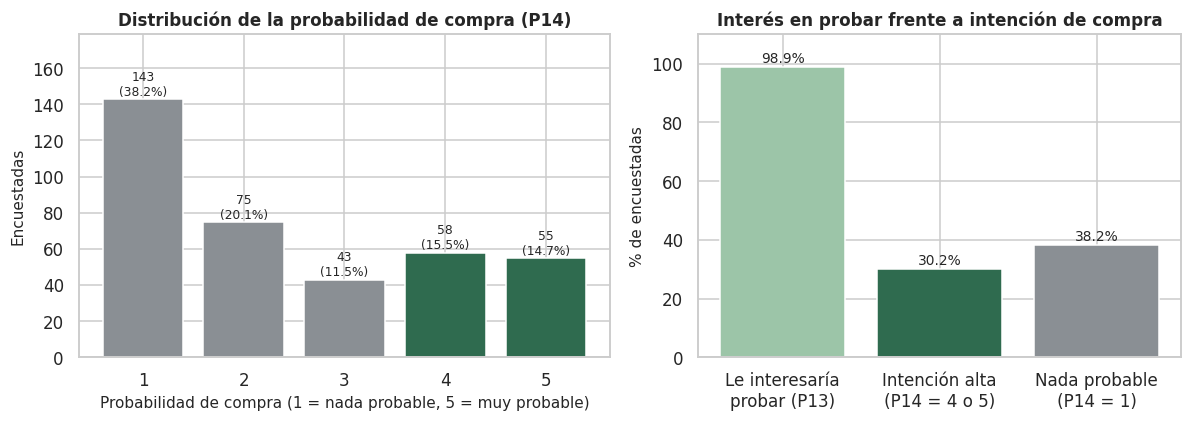

In [ ]:
# Figura 1. Variable objetivo y brecha interés–intención
n = len(df); k_alta = int(df.intencion_alta.sum()); k_int = int(df.interes_probar_bin.sum()); k_nada = int((df.prob_compra == 1).sum())
fig, ax = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.1, 1]})
vc = df.prob_compra.value_counts().sort_index()
cols_b = [GRIS if v < 4 else VERDE for v in vc.index]
ax[0].bar(vc.index.astype(str), vc.values, color=cols_b)
for x, v in zip(vc.index.astype(str), vc.values): ax[0].text(x, v + 2, f"{v}\n({100*v/n:.1f}%)", ha="center", fontsize=8)
ax[0].set_xlabel("Probabilidad de compra (1 = nada probable, 5 = muy probable)"); ax[0].set_ylabel("Encuestadas")
ax[0].set_title("Distribución de la probabilidad de compra (P14)"); ax[0].set_ylim(0, vc.max() * 1.25)
lab = ["Le interesaría\nprobar (P13)", "Intención alta\n(P14 = 4 o 5)", "Nada probable\n(P14 = 1)"]
val = [100 * k_int / n, 100 * k_alta / n, 100 * k_nada / n]
ax[1].bar(lab, val, color=[VERDE_CL, VERDE, GRIS])
for i, v in enumerate(val): ax[1].text(i, v + 1.5, f"{v:.1f}%", ha="center", fontsize=9)
ax[1].set_ylim(0, 110); ax[1].set_ylabel("% de encuestadas"); ax[1].set_title("Interés en probar frente a intención de compra")
savefig("fig01_variable_objetivo_brecha.png")
RES.update({"pct_interes": 100 * k_int / n, "pct_intencion_alta": 100 * k_alta / n, "pct_nada_probable": 100 * k_nada / n,
            "media_P14": float(df.prob_compra.mean()), "sd_P14": float(df.prob_compra.std()), "mediana_P14": float(df.prob_compra.median()),
            "n_alta": k_alta, "n_baja": int(n - k_alta)})

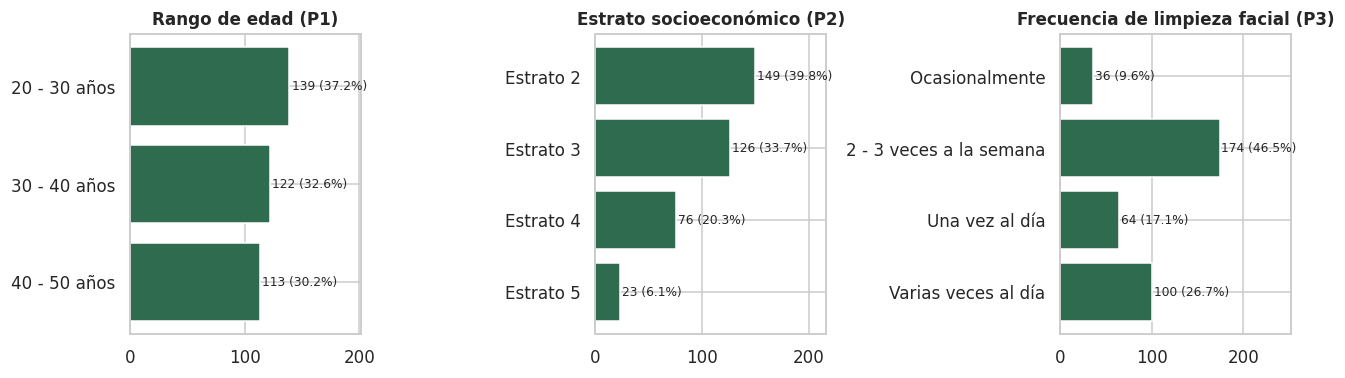

In [ ]:
# Figura 2. Perfil sociodemográfico y hábitos
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
for a, (c, t, o) in zip(ax, [("edad", "Rango de edad (P1)", None), ("estrato", "Estrato socioeconómico (P2)", None),
                             ("frec_limpieza", "Frecuencia de limpieza facial (P3)", ["Ocasionalmente", "2 - 3 veces a la semana", "Una vez al día", "Varias veces al día"])]):
    s = df[c].value_counts() if o is None else df[c].value_counts().reindex(o)
    s = s.sort_index() if o is None else s
    a.barh(s.index.astype(str), s.values, color=VERDE)
    for i, v in enumerate(s.values): a.text(v + 2, i, f"{v} ({100*v/n:.1f}%)", va="center", fontsize=8)
    a.set_title(t); a.set_xlim(0, s.max() * 1.45); a.invert_yaxis()
savefig("fig02_perfil_sociodemografico.png")

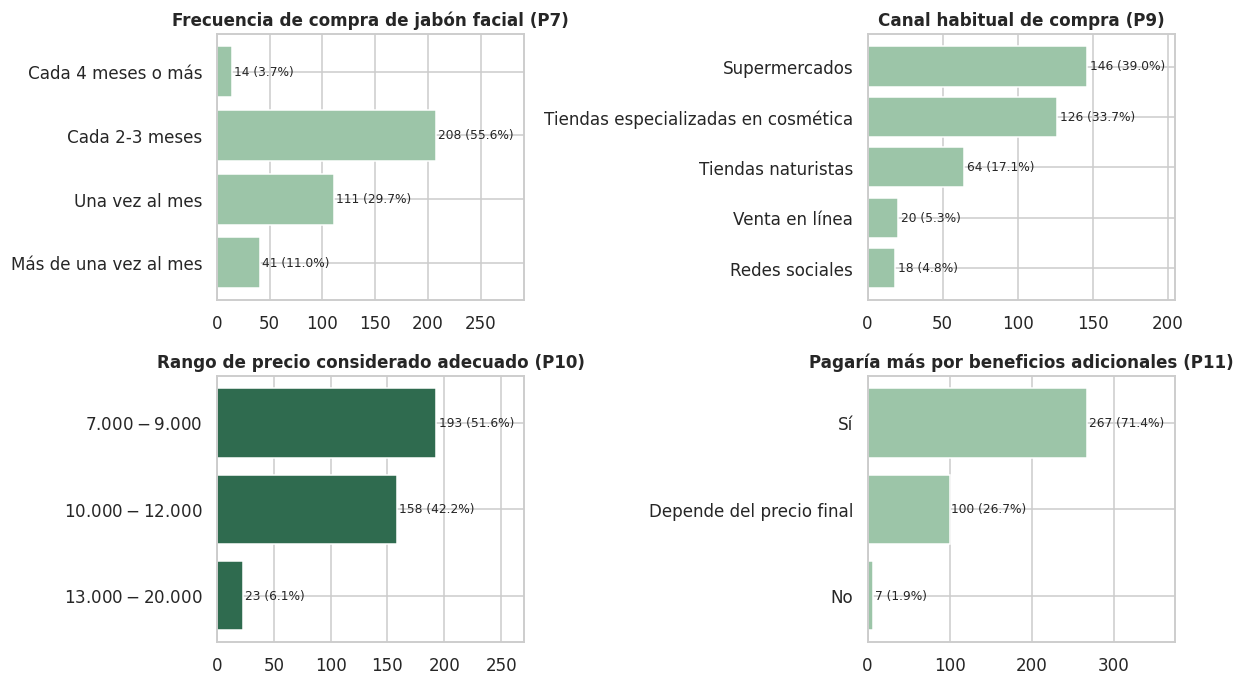

In [ ]:
# Figura 3. Compra, precio y canal
fig, ax = plt.subplots(2, 2, figsize=(11, 6.4))
for a, (c, t, o) in zip(ax.ravel(), [
    ("frec_compra", "Frecuencia de compra de jabón facial (P7)", ["Cada 4 meses o más", "Cada 2-3 meses", "Una vez al mes", "Más de una vez al mes"]),
    ("canal", "Canal habitual de compra (P9)", None),
    ("precio", "Rango de precio considerado adecuado (P10)", ["$7.000 - $9.000", "$10.000 - $12.000", "$13.000 - $20.000"]),
    ("pagar_mas", "Pagaría más por beneficios adicionales (P11)", ["Sí", "Depende del precio final", "No"])]):
    s = df[c].value_counts() if o is None else df[c].value_counts().reindex(o)
    a.barh(s.index.astype(str), s.values, color=VERDE_CL if c != "precio" else VERDE)
    for i, v in enumerate(s.values): a.text(v + 2, i, f"{v} ({100*v/n:.1f}%)", va="center", fontsize=8)
    a.set_title(t); a.set_xlim(0, s.max() * 1.4); a.invert_yaxis()
savefig("fig03_compra_precio_canal.png")
for c in ["precio", "canal", "pagar_mas", "frec_compra"]:
    RES[f"pct_{c}"] = {k: float(v) for k, v in (100 * df[c].value_counts(normalize=True)).items()}

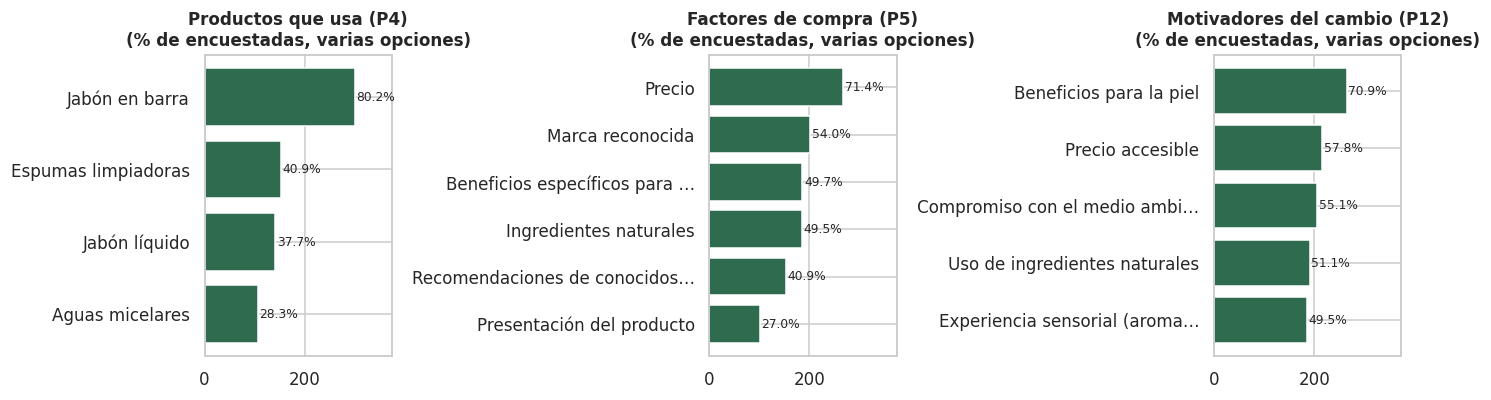

In [ ]:
# Figura 4. Multirrespuesta
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
for a, (src, t) in zip(ax, [("tipo_producto", "Productos que usa (P4)"), ("factores_compra", "Factores de compra (P5)"), ("motivadores", "Motivadores del cambio (P12)")]):
    s = pd.Series({lab: df[k].sum() for k, lab in OPC[src].items()}).sort_values()
    a.barh([l if len(l) < 30 else l[:28] + "…" for l in s.index], s.values, color=VERDE)
    for i, v in enumerate(s.values): a.text(v + 3, i, f"{100*v/n:.1f}%", va="center", fontsize=8)
    a.set_title(t + "\n(% de encuestadas, varias opciones)"); a.set_xlim(0, n * 1.0)
savefig("fig04_multirrespuesta.png")
for src in OPC:
    RES[f"mr_{src}"] = {lab: float(100 * df[k].mean()) for k, lab in OPC[src].items()}

## 7. EDA multivariado
### 7.1 Correlaciones de Pearson y Spearman
Las variables son ordinales o binarias, por lo que **Spearman** es la medida principal y Pearson se reporta como contraste (lo pide la lista de chequeo).

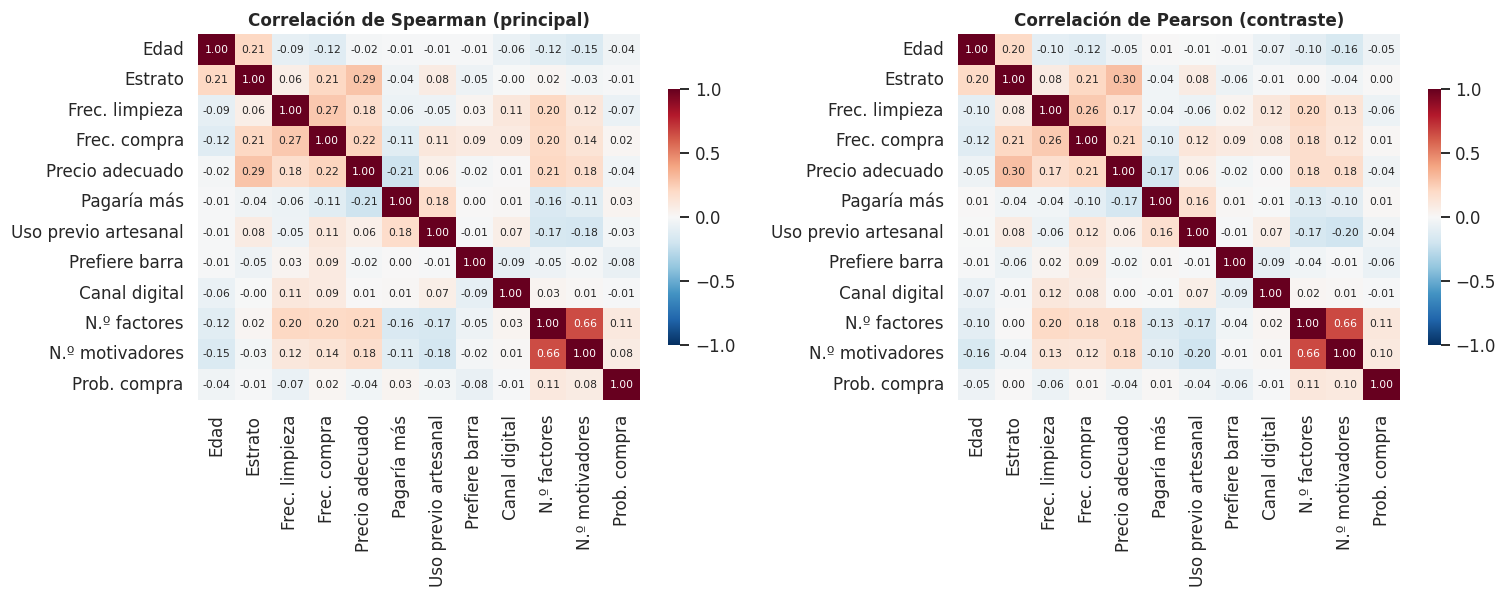

,Variable,Spearman ρ,p Spearman,Pearson r,p Pearson,p Spearman (Holm)
9,N.º factores,0.1064,0.0397,0.1141,0.0273,0.4363
10,N.º motivadores,0.0828,0.1098,0.0966,0.0619,1.0000
7,Prefiere barra,-0.0751,0.1474,-0.0641,0.2159,1.0000
2,Frec. limpieza,-0.0687,0.1847,-0.0611,0.2386,1.0000
0,Edad,-0.0445,0.3907,-0.0515,0.3203,1.0000
4,Precio adecuado,-0.0384,0.4595,-0.0435,0.4013,1.0000
6,Uso previo artesanal,-0.0296,0.5677,-0.0424,0.4133,1.0000
5,Pagaría más,0.0256,0.6223,0.0114,0.8256,1.0000
3,Frec. compra,0.0210,0.6850,0.0107,0.8370,1.0000
1,Estrato,-0.0092,0.8587,0.0041,0.9377,1.0000


In [ ]:
NUM = ["edad_ord", "estrato_num", "frec_limpieza_ord", "frec_compra_ord", "precio_ord", "pagar_mas_ord",
       "uso_previo", "pref_barra", "canal_digital", "n_factores", "n_motivadores", "prob_compra"]
ETQ = {"edad_ord": "Edad", "estrato_num": "Estrato", "frec_limpieza_ord": "Frec. limpieza", "frec_compra_ord": "Frec. compra",
       "precio_ord": "Precio adecuado", "pagar_mas_ord": "Pagaría más", "uso_previo": "Uso previo artesanal", "pref_barra": "Prefiere barra",
       "canal_digital": "Canal digital", "n_factores": "N.º factores", "n_motivadores": "N.º motivadores", "prob_compra": "Prob. compra"}
pear = df[NUM].corr("pearson"); spea = df[NUM].corr("spearman")
fig, ax = plt.subplots(1, 2, figsize=(14, 5.6))
for a, m, t in zip(ax, [spea, pear], ["Spearman (principal)", "Pearson (contraste)"]):
    sns.heatmap(m.rename(index=ETQ, columns=ETQ), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=a,
                cbar_kws={"shrink": .7}, annot_kws={"size": 7}); a.set_title(f"Correlación de {t}")
savefig("fig05_correlaciones_spearman_pearson.png")
pear.round(3).to_csv(TAB / "correlacion_pearson.csv", encoding="utf-8-sig"); spea.round(3).to_csv(TAB / "correlacion_spearman.csv", encoding="utf-8-sig")

# Correlación de cada variable con la probabilidad de compra (Spearman, p ajustado por Holm)
filas = []
for c in [x for x in NUM if x != "prob_compra"]:
    r, p = stats.spearmanr(df[c], df.prob_compra); rp, pp = stats.pearsonr(df[c], df.prob_compra)
    filas.append((ETQ[c], r, p, rp, pp))
cor_obj = pd.DataFrame(filas, columns=["Variable", "Spearman ρ", "p Spearman", "Pearson r", "p Pearson"])
cor_obj["p Spearman (Holm)"] = multipletests(cor_obj["p Spearman"], method="holm")[1]
cor_obj = cor_obj.sort_values("Spearman ρ", key=abs, ascending=False).round(4)
cor_obj.to_csv(TAB / "correlacion_con_prob_compra.csv", index=False, encoding="utf-8-sig")
RES["cor_obj_top"] = cor_obj.head(3).to_dict("records")
RES["cor_obj_signif_holm"] = cor_obj.loc[cor_obj["p Spearman (Holm)"] < 0.05, "Variable"].tolist()
off = spea.where(~np.eye(len(NUM), dtype=bool)).abs().stack()
RES["max_abs_spearman_pares"] = float(off.max())
RES["max_abs_spearman_sin_obj"] = float(spea.drop("prob_compra").drop(columns="prob_compra").where(~np.eye(len(NUM) - 1, dtype=bool)).abs().stack().max())
cor_obj

### 7.2 Asociación con la variable objetivo (chi-cuadrado, V de Cramér, corrección de Holm)

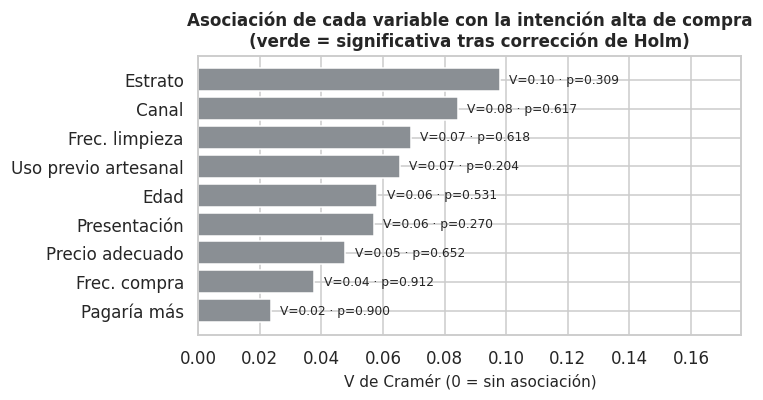

,Variable,χ²,gl,p (chi²),p (Monte Carlo),V de Cramér,% celdas con esperado < 5,p (Holm)
1,Estrato,3.5888,3,0.3094,0.3103,0.0980,0.0,1.0
6,Canal,2.6584,4,0.6165,0.6312,0.0843,0.0,1.0
2,Frec. limpieza,1.7863,3,0.6179,0.6127,0.0691,0.0,1.0
3,Uso previo artesanal,1.6097,1,0.2045,0.2104,0.0656,0.0,1.0
0,Edad,1.2674,2,0.5306,0.5432,0.0582,0.0,1.0
5,Presentación,1.2168,1,0.2700,0.3883,0.0570,0.0,1.0
7,Precio adecuado,0.8555,2,0.6520,0.6757,0.0478,0.0,1.0
4,Frec. compra,0.5313,3,0.9120,0.9205,0.0377,12.5,1.0
8,Pagaría más,0.2099,2,0.9004,0.9060,0.0237,33.3,1.0


In [ ]:
CATS = {"edad": "Edad", "estrato": "Estrato", "frec_limpieza": "Frec. limpieza", "uso_previo_artesanal": "Uso previo artesanal",
        "frec_compra": "Frec. compra", "presentacion": "Presentación", "canal": "Canal", "precio": "Precio adecuado", "pagar_mas": "Pagaría más"}
filas = []
for c, et in CATS.items():
    tab = pd.crosstab(df[c], df.intencion_alta)
    chi2, p, dof, esp = stats.chi2_contingency(tab, correction=False)
    v = np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))
    # p Monte Carlo (permutando la variable objetivo) como contraste cuando hay frecuencias esperadas bajas
    perm = np.array([stats.chi2_contingency(pd.crosstab(df[c], rng.permutation(df.intencion_alta.values)), correction=False)[0] for _ in range(2000)])
    p_mc = (1 + (perm >= chi2).sum()) / (1 + len(perm))
    filas.append((et, chi2, dof, p, p_mc, v, round(100 * (esp < 5).mean(), 1)))
chi = pd.DataFrame(filas, columns=["Variable", "χ²", "gl", "p (chi²)", "p (Monte Carlo)", "V de Cramér", "% celdas con esperado < 5"])
chi["p (Holm)"] = multipletests(chi["p (chi²)"], method="holm")[1]
chi = chi.sort_values("V de Cramér", ascending=False).round(4)
chi.to_csv(TAB / "chi2_vs_intencion_alta.csv", index=False, encoding="utf-8-sig")
RES["chi2"] = chi.to_dict("records")
RES["chi2_signif_holm"] = chi.loc[chi["p (Holm)"] < 0.05, "Variable"].tolist()
RES["chi2_signif_sin_ajuste"] = chi.loc[chi["p (chi²)"] < 0.05, "Variable"].tolist()
fig, ax = plt.subplots(figsize=(7, 3.8))
cc = [VERDE if p < 0.05 else GRIS for p in chi["p (Holm)"]]
ax.barh(chi["Variable"], chi["V de Cramér"], color=cc); ax.invert_yaxis()
for i, (v, p) in enumerate(zip(chi["V de Cramér"], chi["p (chi²)"])): ax.text(v + .003, i, f"V={v:.2f} · p={p:.3f}", va="center", fontsize=8)
ax.set_xlim(0, chi["V de Cramér"].max() * 1.8); ax.set_xlabel("V de Cramér (0 = sin asociación)")
ax.set_title("Asociación de cada variable con la intención alta de compra\n(verde = significativa tras corrección de Holm)")
savefig("fig06_cramer_v_objetivo.png")
chi

In [ ]:
# Asociaciones de los factores de multirrespuesta con la intención alta (chi² 2×2, Holm)
filas = []
for src, mp in OPC.items():
    for k, lab in mp.items():
        tab = pd.crosstab(df[k], df.intencion_alta)
        if tab.shape != (2, 2): continue
        chi2, p, _, _ = stats.chi2_contingency(tab, correction=False)
        filas.append((src, lab, 100 * df.loc[df[k] == 1, "intencion_alta"].mean(), 100 * df.loc[df[k] == 0, "intencion_alta"].mean(), p))
mr = pd.DataFrame(filas, columns=["Pregunta", "Opción", "% intención alta si la marca", "% intención alta si no la marca", "p"])
mr["p (Holm)"] = multipletests(mr["p"], method="holm")[1]
mr = mr.round(4).sort_values("p"); mr.to_csv(TAB / "chi2_multirrespuesta_vs_objetivo.csv", index=False, encoding="utf-8-sig")
RES["mr_signif_holm"] = mr.loc[mr["p (Holm)"] < 0.05, "Opción"].tolist()
RES["mr_min_p"] = float(mr.p.min()); RES["mr_min_p_holm"] = float(mr["p (Holm)"].min()); RES["mr_min_opcion"] = mr.iloc[0]["Opción"]
mr

,Pregunta,Opción,% intención alta si la marca,% intención alta si no la marca,p,p (Holm)
8,factores_compra,Recomendaciones de conocidos o expertos,39.8693,23.5294,0.0007,0.0107
11,motivadores,Precio accesible,34.7222,24.0506,0.0264,0.3698
2,tipo_producto,Espumas limpiadoras,35.2941,26.6968,0.0750,0.9755
9,factores_compra,Presentación del producto,36.6337,27.8388,0.1001,1.0000
4,factores_compra,Precio,28.0899,35.5140,0.1576,1.0000
7,factores_compra,Beneficios específicos para la piel,33.3333,27.1277,0.1913,1.0000
12,motivadores,Compromiso con el medio ambiente,33.0097,26.7857,0.1923,1.0000
6,factores_compra,Ingredientes naturales,32.9730,27.5132,0.2503,1.0000
3,tipo_producto,Aguas micelares,33.9623,28.7313,0.3208,1.0000
13,motivadores,Uso de ingredientes naturales,32.4607,27.8689,0.3337,1.0000


### 7.3 Multicolinealidad (VIF)

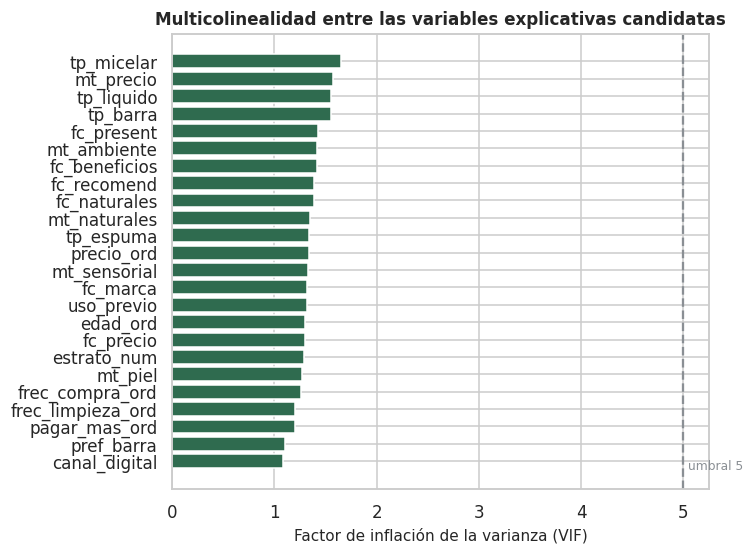

VIF máximo = 1.65 (tp_micelar); variables con VIF > 5: 0 de 24


,Variable,VIF
12,tp_micelar,1.65
20,mt_precio,1.57
10,tp_liquido,1.55
9,tp_barra,1.55
18,fc_present,1.42
21,mt_ambiente,1.41
16,fc_beneficios,1.41
17,fc_recomend,1.39
15,fc_naturales,1.39
22,mt_naturales,1.35


In [ ]:
VIF_VARS = ["edad_ord", "estrato_num", "frec_limpieza_ord", "frec_compra_ord", "precio_ord", "pagar_mas_ord", "uso_previo", "pref_barra", "canal_digital"] \
           + list(OPC["tipo_producto"]) + list(OPC["factores_compra"]) + list(OPC["motivadores"])
X = sm.add_constant(df[VIF_VARS].astype(float))
vif = pd.DataFrame({"Variable": VIF_VARS, "VIF": [variance_inflation_factor(X.values, i + 1) for i in range(len(VIF_VARS))]}).sort_values("VIF", ascending=False)
vif.round(3).to_csv(TAB / "vif.csv", index=False, encoding="utf-8-sig")
RES["vif_max"] = float(vif.VIF.max()); RES["vif_max_var"] = vif.iloc[0]["Variable"]; RES["vif_n_gt5"] = int((vif.VIF > 5).sum()); RES["vif_n"] = len(VIF_VARS)
fig, ax = plt.subplots(figsize=(7, 5.2))
ax.barh(vif.Variable, vif.VIF, color=[ACENTO if v > 5 else VERDE for v in vif.VIF]); ax.invert_yaxis()
ax.axvline(5, ls="--", color=GRIS); ax.text(5.05, len(vif) - .5, "umbral 5", fontsize=8, color=GRIS)
ax.set_xlabel("Factor de inflación de la varianza (VIF)"); ax.set_title("Multicolinealidad entre las variables explicativas candidatas")
savefig("fig07_vif.png")
print(f"VIF máximo = {RES['vif_max']:.2f} ({RES['vif_max_var']}); variables con VIF > 5: {RES['vif_n_gt5']} de {RES['vif_n']}")
vif.round(2)

### 7.4 Desbalance de clases y dimensión temporal

In [ ]:
cnt = df.intencion_alta.value_counts().sort_index()
RES["ratio_desbalance"] = float(cnt.max() / cnt.min())
print(cnt.rename({0: "Intención baja/media (P14 ≤ 3)", 1: "Intención alta (P14 ≥ 4)"}))
print(f"Razón mayoritaria:minoritaria = {RES['ratio_desbalance']:.2f} : 1")

RES["periodo_texto"] = PERIODO
print("El archivo depurado no tiene marca temporal y, según el formulario original, las respuestas se recogieron en 3 días: no hay serie temporal; no aplica tendencia ni estacionalidad.")

intencion_alta
Intención baja/media (P14 ≤ 3)    261
Intención alta (P14 ≥ 4)          113
Name: count, dtype: int64
Razón mayoritaria:minoritaria = 2.31 : 1
El archivo depurado no tiene marca temporal y, según el formulario original, las respuestas se recogieron en 3 días: no hay serie temporal; no aplica tendencia ni estacionalidad.


## 8. Robustez: ¿los hallazgos se repiten en subgrupos y cortes de los datos?
Se compara la proporción de **intención alta** con intervalos de Wilson del 95 % por edad, estrato, uso previo y disposición a pagar.

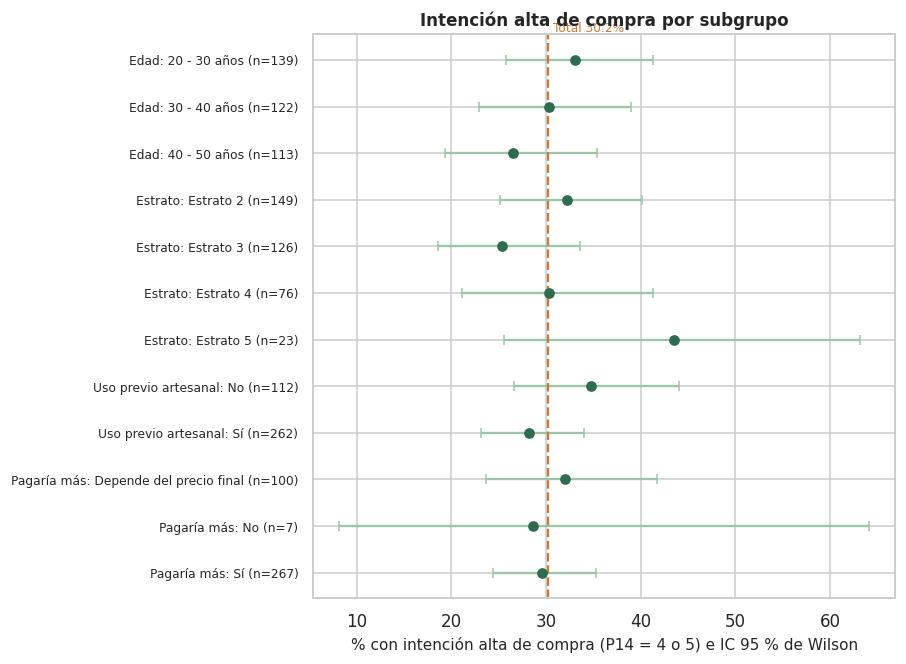

,Subgrupo,Categoría,n,% intención alta,IC95 inf.,IC95 sup.,Media P14
0,Edad,20 - 30 años,139,33.1,25.8,41.3,2.6
1,Edad,30 - 40 años,122,30.3,22.9,39.0,2.5
2,Edad,40 - 50 años,113,26.5,19.3,35.4,2.4
3,Estrato,Estrato 2,149,32.2,25.2,40.1,2.6
4,Estrato,Estrato 3,126,25.4,18.6,33.6,2.4
5,Estrato,Estrato 4,76,30.3,21.1,41.3,2.5
6,Estrato,Estrato 5,23,43.5,25.6,63.2,2.7
7,Uso previo artesanal,No,112,34.8,26.6,44.0,2.6
8,Uso previo artesanal,Sí,262,28.2,23.1,34.0,2.4
9,Pagaría más,Depende del precio final,100,32.0,23.7,41.7,2.4


In [ ]:
filas = []
def sub(var, etiqueta, mapa=None):
    for g, d in df.groupby(var):
        k, m = int(d.intencion_alta.sum()), len(d); lo, hi = wilson(k, m)
        filas.append((etiqueta, str(mapa[g] if mapa else g), m, 100 * k / m, 100 * lo, 100 * hi, round(d.prob_compra.mean(), 2)))
sub("edad", "Edad"); sub("estrato", "Estrato"); sub("uso_previo_artesanal", "Uso previo artesanal"); sub("pagar_mas", "Pagaría más")
rob = pd.DataFrame(filas, columns=["Subgrupo", "Categoría", "n", "% intención alta", "IC95 inf.", "IC95 sup.", "Media P14"]).round(1)
rob.to_csv(TAB / "robustez_subgrupos.csv", index=False, encoding="utf-8-sig")
RES["rob"] = rob.to_dict("records")
tot = 100 * df.intencion_alta.mean()
RES["rob_rango"] = [float(rob["% intención alta"].min()), float(rob["% intención alta"].max())]
# ¿Algún subgrupo con IC que excluya el promedio global?
fuera = rob[(rob["IC95 inf."] > tot) | (rob["IC95 sup."] < tot)]
RES["rob_fuera_ic"] = fuera[["Subgrupo", "Categoría"]].values.tolist()
fig, ax = plt.subplots(figsize=(8.4, 6.2))
y = np.arange(len(rob))[::-1]
ax.errorbar(rob["% intención alta"], y, xerr=[rob["% intención alta"] - rob["IC95 inf."], rob["IC95 sup."] - rob["% intención alta"]],
            fmt="o", color=VERDE, ecolor=VERDE_CL, capsize=3)
ax.axvline(tot, ls="--", color=ACENTO); ax.text(tot + .5, y.max() + .6, f"Total {tot:.1f}%", color=ACENTO, fontsize=8)
ax.set_yticks(y); ax.set_yticklabels([f"{a}: {b} (n={n_})" for a, b, n_ in zip(rob.Subgrupo, rob.Categoría, rob.n)], fontsize=8)
ax.set_xlabel("% con intención alta de compra (P14 = 4 o 5) e IC 95 % de Wilson"); ax.set_title("Intención alta de compra por subgrupo")
savefig("fig08_robustez_subgrupos.png")
rob

In [ ]:
# Prueba global entre edades sobre la media de P14 (Kruskal–Wallis), como contraste adicional
kw_edad = stats.kruskal(*[g.prob_compra.values for _, g in df.groupby("edad")])
RES["kw_edad_p"] = float(kw_edad.pvalue)
# Estabilidad de la correlación principal entre estratos de edad
est = {g: float(stats.spearmanr(d.pagar_mas_ord, d.prob_compra)[0]) for g, d in df.groupby("edad")}
RES["spearman_pagarmas_por_edad"] = est
print(f"Kruskal–Wallis P14 por edad: p = {kw_edad.pvalue:.3f}")
print("ρ(pagaría más, P14) por edad:", {k: round(v, 3) for k, v in est.items()})

Kruskal–Wallis P14 por edad: p = 0.680
ρ(pagaría más, P14) por edad: {'20 - 30 años': -0.078, '30 - 40 años': 0.107, '40 - 50 años': 0.066}


## 9. KPIs del enfoque descriptivo
Cada KPI tiene fórmula, valor con intervalo de confianza y **referencia**.

In [ ]:
n = len(df)
def prop_row(nombre, formula, k, ref=None, ref_txt="—"):
    lo, hi = wilson(k, n); p = k / n
    pv = stats.binomtest(k, n, ref).pvalue if ref is not None else np.nan
    return (nombre, formula, f"{100*p:.1f} %", f"[{100*lo:.1f} ; {100*hi:.1f}]", ref_txt, pv)

k_top2 = int(df.intencion_alta.sum()); k_top3 = int((df.prob_compra >= 3).sum())
bs = np.array([rng.choice(df.prob_compra.values, n).mean() for _ in range(5000)])
kp = [
 prop_row("KPI 1 · Interés en probar", "Σ(P13 = Sí) / n", int(df.interes_probar_bin.sum())),
 prop_row("KPI 2 · Intención alta de compra", "Σ(P14 ≥ 4) / n", k_top2, None, "Subgrupos de edad y estrato"),
 prop_row("KPI 3 · Intención media-alta", "Σ(P14 ≥ 3) / n", k_top3, None, "Subgrupos de edad y estrato"),
 prop_row("KPI 4 · Disposición a pagar más", "Σ(P11 = Sí) / n", int((df.pagar_mas == "Sí").sum())),
 prop_row("KPI 5 · Experiencia previa con artesanales", "Σ(P6 = Sí) / n", int(df.uso_previo.sum())),
 prop_row("KPI 6 · Compra por canal digital", "Σ(P9 ∈ {en línea, redes}) / n", int(df.canal_digital.sum())),
 prop_row("KPI 7 · Precio adecuado en el rango más bajo", "Σ(P10 = $7.000–$9.000) / n", int((df.precio_ord == 1).sum())),
]
kpi = pd.DataFrame(kp, columns=["KPI", "Fórmula", "Valor", "IC 95 % (Wilson)", "Referencia", "p"])
extra = pd.DataFrame([("KPI 8 · Probabilidad de compra media (1–5)", "Σ P14 / n", f"{df.prob_compra.mean():.2f}",
                       f"[{np.percentile(bs,2.5):.2f} ; {np.percentile(bs,97.5):.2f}]", "3,0 = punto medio de la escala", stats.ttest_1samp(df.prob_compra, 3).pvalue),
                      ("KPI 9 · Brecha interés–intención", "KPI 1 − KPI 2 (puntos porcentuales)", f"{100*(df.interes_probar_bin.mean()-df.intencion_alta.mean()):.1f} pp", "—", "0 pp (interés = intención)", np.nan)],
                     columns=kpi.columns)
kpi = pd.concat([kpi, extra], ignore_index=True)
kpi["p"] = kpi["p"].round(4)
kpi.to_csv(TAB / "kpis_descriptivos.csv", index=False, encoding="utf-8-sig")
RES["kpi"] = kpi.fillna("").to_dict("records")
RES["pct_top3"] = 100 * k_top3 / n; RES["n_top3"] = k_top3
RES["ic_top2"] = [100 * x for x in wilson(k_top2, n)]
RES["media_ic"] = [float(np.percentile(bs, 2.5)), float(np.percentile(bs, 97.5))]
RES["p_media_vs3"] = float(stats.ttest_1samp(df.prob_compra, 3).pvalue)
RES["pct_digital"] = 100 * df.canal_digital.mean(); RES["pct_uso_previo"] = 100 * df.uso_previo.mean()
RES["pct_pagar_si"] = 100 * (df.pagar_mas == "Sí").mean(); RES["pct_precio_bajo"] = 100 * (df.precio_ord == 1).mean()
RES["pct_barra"] = 100 * df.pref_barra.mean()
kpi

,KPI,Fórmula,Valor,IC 95 % (Wilson),Referencia,p
0,KPI 1 · Interés en probar,Σ(P13 = Sí) / n,98.9 %,[97.3 ; 99.6],—,NaN
1,KPI 2 · Intención alta de compra,Σ(P14 ≥ 4) / n,30.2 %,[25.8 ; 35.0],Subgrupos de edad y estrato,NaN
2,KPI 3 · Intención media-alta,Σ(P14 ≥ 3) / n,41.7 %,[36.8 ; 46.8],Subgrupos de edad y estrato,NaN
3,KPI 4 · Disposición a pagar más,Σ(P11 = Sí) / n,71.4 %,[66.6 ; 75.7],—,NaN
4,KPI 5 · Experiencia previa con artesanales,Σ(P6 = Sí) / n,70.1 %,[65.2 ; 74.5],—,NaN
5,KPI 6 · Compra por canal digital,"Σ(P9 ∈ {en línea, redes}) / n",10.2 %,[7.5 ; 13.6],—,NaN
6,KPI 7 · Precio adecuado en el rango más bajo,Σ(P10 = $7.000–$9.000) / n,51.6 %,[46.5 ; 56.6],—,NaN
7,KPI 8 · Probabilidad de compra media (1–5),Σ P14 / n,2.48,[2.34 ; 2.64],"3,0 = punto medio de la escala",0.0
8,KPI 9 · Brecha interés–intención,KPI 1 − KPI 2 (puntos porcentuales),68.7 pp,—,0 pp (interés = intención),NaN


## 10. Hallazgos en el lenguaje del problema y la decisión que sugiere cada uno
Las cifras se imprimen desde el código. Los `assert` evitan que el texto contradiga los resultados si alguien cambia los datos o los parámetros.

In [ ]:
assert RES["pct_interes"] > 95 and RES["pct_intencion_alta"] < 40         # hallazgo 1
assert len(RES["chi2_signif_holm"]) == 0 and len(RES["cor_obj_signif_holm"]) == 0  # hallazgo 2 (ninguna sociodemográfica/hábitos sobrevive a Holm)
assert RES["mr_signif_holm"] == ["Recomendaciones de conocidos o expertos"]
H = [
 ("1. Casi todas quieren probar el jabón, pero pocas dicen que lo comprarían.",
  f"{RES['pct_interes']:.1f} % se interesa en probarlo, pero solo {RES['pct_intencion_alta']:.1f} % tiene intención alta de compra (P14 = 4 o 5) y {RES['pct_nada_probable']:.1f} % la califica como 'nada probable'.",
  "La demanda potencial (objetivo 3) no debe calcularse con el 'Sí' a probar. Se usará la probabilidad de compra (P14) y tres escenarios: pesimista (solo P14 = 5), probable (P14 ≥ 4) y optimista (P14 ≥ 3)."),
 ("2. La edad, el estrato y los hábitos no explican la intención de compra; lo que sí se asocia es la recomendación de terceros.",
  f"Ninguna variable sociodemográfica ni de hábitos queda asociada con la intención alta tras corregir por comparaciones múltiples (Holm), y la intención alta va de {RES['rob_rango'][0]:.1f} % a {RES['rob_rango'][1]:.1f} % entre subgrupos con intervalos traslapados. La excepción es 'Recomendaciones de conocidos o expertos' como factor de compra: la intención alta es {mr.iloc[0]['% intención alta si la marca']:.1f} % entre quienes lo marcan y {mr.iloc[0]['% intención alta si no la marca']:.1f} % entre quienes no (p ajustado = {RES['mr_min_p_holm']:.3f}).",
  "No conviene segmentar la venta por edad o estrato. Sí conviene apoyar la comunicación de Aromaclean en prescriptores y recomendaciones (boca a boca, expertas en cuidado de la piel). Es una asociación, no prueba causalidad; el objetivo 2 la pondrá a prueba junto con las demás variables."),
 ("3. La mitad ve adecuado el precio más bajo, aunque la mayoría dice que pagaría más por beneficios adicionales.",
  f"{RES['pct_precio_bajo']:.1f} % considera adecuado un precio de $7.000 a $9.000; {RES['pct_pagar_si']:.1f} % pagaría más por beneficios adicionales y {RES['pct_pagar_mas']['Depende del precio final']:.1f} % responde 'depende del precio final'.",
  "El precio de lanzamiento debe probarse dentro de $7.000–$12.000 en el modelo financiero (objetivo 4), con sensibilidad al precio como variable crítica. La disposición a pagar más se tratará como escenario optimista, no como supuesto base, porque una de cada cuatro encuestadas condiciona su respuesta al precio final."),
]
for t, ev, dec in H:
    print(t); print("  Evidencia:", ev); print("  Decisión:", dec, "\n")
RES["hallazgos"] = [{"titulo": t, "evidencia": e, "decision": d} for t, e, d in H]

1. Casi todas quieren probar el jabón, pero pocas dicen que lo comprarían.
  Evidencia: 98.9 % se interesa en probarlo, pero solo 30.2 % tiene intención alta de compra (P14 = 4 o 5) y 38.2 % la califica como 'nada probable'.
  Decisión: La demanda potencial (objetivo 3) no debe calcularse con el 'Sí' a probar. Se usará la probabilidad de compra (P14) y tres escenarios: pesimista (solo P14 = 5), probable (P14 ≥ 4) y optimista (P14 ≥ 3). 

2. La edad, el estrato y los hábitos no explican la intención de compra; lo que sí se asocia es la recomendación de terceros.
  Evidencia: Ninguna variable sociodemográfica ni de hábitos queda asociada con la intención alta tras corregir por comparaciones múltiples (Holm), y la intención alta va de 25.4 % a 43.5 % entre subgrupos con intervalos traslapados. La excepción es 'Recomendaciones de conocidos o expertos' como factor de compra: la intención alta es 39.9 % entre quienes lo marcan y 23.5 % entre quienes no (p ajustado = 0.011).
  Decisión: No co

## 11. Protocolo de evaluación en código (se fija ahora, se usa en el ACA 2)
Se deja fija la partición (20 % de prueba, estratificada, semilla 42), la validación cruzada repetida 5×2, las dos líneas base y el `Pipeline` donde se ajustarán imputación, escalado y codificación. **El conjunto de prueba no se toca aquí.**

In [ ]:
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, matthews_corrcoef, brier_score_loss
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

FEATS = ["edad_ord", "estrato_num", "frec_limpieza_ord", "frec_compra_ord", "precio_ord", "pagar_mas_ord",
         "uso_previo", "pref_barra", "canal_digital"] + list(OPC["tipo_producto"]) + list(OPC["factores_compra"]) + list(OPC["motivadores"])
X, y = df[FEATS], df["intencion_alta"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
pd.concat([pd.DataFrame({"indice": X_tr.index, "conjunto": "entrenamiento"}),
           pd.DataFrame({"indice": X_te.index, "conjunto": "prueba"})]).to_csv(TAB / "particion_fija.csv", index=False)
print(f"Entrenamiento: {len(X_tr)} (alta = {y_tr.mean():.3f}) | Prueba: {len(X_te)} (alta = {y_te.mean():.3f})")

# Validación cruzada estratificada repetida 5x2 = 10 particiones
cv = RepeatedStratifiedKFold(n_splits=2, n_repeats=5, random_state=SEED)

# Pipeline del ACA 2: lo que aprende de los datos se ajusta SOLO dentro de cada pliegue
prep = ColumnTransformer([("esc", StandardScaler(), ["edad_ord", "estrato_num", "frec_limpieza_ord", "frec_compra_ord", "precio_ord", "pagar_mas_ord"])],
                         remainder="passthrough")
pipeline_aca2 = Pipeline([("prep", prep), ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED))])
print("Pipeline definido (sin entrenar):", [n for n, _ in pipeline_aca2.steps])

def evaluar(modelo, cols):
    filas = []
    for tr, va in cv.split(X_tr[cols], y_tr):
        m = modelo(); m.fit(X_tr.iloc[tr][cols], y_tr.iloc[tr])
        p = m.predict_proba(X_tr.iloc[va][cols])[:, 1]; yh = (p >= 0.5).astype(int); yv = y_tr.iloc[va]
        filas.append({"AUC-ROC": roc_auc_score(yv, p), "AUC-PR": average_precision_score(yv, p), "F1-macro": f1_score(yv, yh, average="macro"),
                      "MCC": matthews_corrcoef(yv, yh), "Brier": brier_score_loss(yv, p)})
    return pd.DataFrame(filas)

base1 = evaluar(lambda: DummyClassifier(strategy="prior"), ["fc_recomend"])
base2 = evaluar(lambda: LogisticRegression(max_iter=1000), ["fc_recomend"])
res_base = pd.concat({"Linea base 1: clase mas frecuente": base1.agg(["mean", "std"]).T,
                      "Linea base 2: solo recomendaciones": base2.agg(["mean", "std"]).T}).round(3)
res_base.to_csv(TAB / "lineas_base_cv5x2.csv", encoding="utf-8-sig")
RES["lineabase"] = {"n_train": int(len(X_tr)), "n_test": int(len(X_te)),
                    "auc_b1": float(base1["AUC-ROC"].mean()), "auc_b2": float(base2["AUC-ROC"].mean()),
                    "auc_b2_ic": [float(base2["AUC-ROC"].quantile(.025)), float(base2["AUC-ROC"].quantile(.975))]}
res_base

Entrenamiento: 299 (alta = 0.301) | Prueba: 75 (alta = 0.307)
Pipeline definido (sin entrenar): ['prep', 'clf']


mean    std
Linea base 1: clase mas frecuente  AUC-ROC   0.500  0.000
                                   AUC-PR    0.301  0.001
                                   F1-macro  0.411  0.000
                                   MCC       0.000  0.000
                                   Brier     0.210  0.000
Linea base 2: solo recomendaciones AUC-ROC   0.586  0.035
                                   AUC-PR    0.349  0.022
                                   F1-macro  0.411  0.000
                                   MCC       0.000  0.000
                                   Brier     0.207  0.004

### Bitácora de decisiones exportable

In [ ]:
bitacora = pd.DataFrame([
 (FECHA_OBTENCION, "ETL, EDA y pruebas en Python (Colab y GitHub); Power BI solo para el dashboard", "Seguir con Power Query y R", "La entrega exige Python/Colab/GitHub y reproducibilidad", "Este cuaderno"),
 (FECHA_OBTENCION, "Variable objetivo intencion_alta = P14 >= 4", "P13; P14 continua; P14 >= 3", f"P13 casi constante ({RES['pct_interes']:.1f} % si)", "Figura 1"),
 (FECHA_OBTENCION, "Conservar respuestas identicas", "Eliminar todas las copias", f"Cambio < {RES['alt_dup_delta_max']:.2f} pp", "Seccion 5"),
 (FECHA_OBTENCION, "Unificar Si/si/Sí", "Dejar originales", "Evitar categorias duplicadas", "Seccion 4"),
 (FECHA_OBTENCION, "Sin imputar/escalar en el ETL", "Transformar toda la base", "Evitar fuga; ira en Pipeline", "Seccion 11"),
 (FECHA_OBTENCION, "Spearman principal, Pearson contraste; Holm en pruebas multiples", "Solo Pearson; sin correccion", "Variables ordinales; muchas pruebas", "Seccion 7"),
 (FECHA_OBTENCION, "AUC-ROC principal, CV 5x2, prueba 20 % estratificada", "F1-macro; TimeSeriesSplit", "Sin fechas; clase positiva 30 %", "Seccion 11"),
], columns=["Fecha", "Decision", "Alternativas consideradas", "Por que", "Evidencia"])
bitacora.to_csv(TAB / "bitacora_decisiones.csv", index=False, encoding="utf-8-sig")
bitacora

,Fecha,Decision,Alternativas consideradas,Por que,Evidencia
0,2026-10-25,"ETL, EDA y pruebas en Python (Colab y GitHub);...",Seguir con Power Query y R,La entrega exige Python/Colab/GitHub y reprodu...,Este cuaderno
1,2026-10-25,Variable objetivo intencion_alta = P14 >= 4,P13; P14 continua; P14 >= 3,P13 casi constante (98.9 % si),Figura 1
2,2026-10-25,Conservar respuestas identicas,Eliminar todas las copias,Cambio < 0.26 pp,Seccion 5
3,2026-10-25,Unificar Si/si/Sí,Dejar originales,Evitar categorias duplicadas,Seccion 4
4,2026-10-25,Sin imputar/escalar en el ETL,Transformar toda la base,Evitar fuga; ira en Pipeline,Seccion 11
5,2026-10-25,"Spearman principal, Pearson contraste; Holm en...",Solo Pearson; sin correccion,Variables ordinales; muchas pruebas,Seccion 7
6,2026-10-25,"AUC-ROC principal, CV 5x2, prueba 20 % estrati...",F1-macro; TimeSeriesSplit,Sin fechas; clase positiva 30 %,Seccion 11


## 12. Exportación de resultados

In [ ]:
cols_exp = COLS + [c for c in df.columns if c not in COLS ]
df[cols_exp].to_csv(PROC / "aromaclean_limpio.csv", index=False, encoding="utf-8-sig")
RES["archivos_figuras"] = sorted(p.name for p in FIG.glob("*.png"))
with open(TAB / "resultados.json", "w", encoding="utf-8") as f:
    json.dump(RES, f, ensure_ascii=False, indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("Base limpia:", df[cols_exp].shape, "→ data/processed/aromaclean_limpio.csv")
print("Figuras:", RES["archivos_figuras"])

Base limpia: (374, 45) → data/processed/aromaclean_limpio.csv
Figuras: ['fig01_variable_objetivo_brecha.png', 'fig02_perfil_sociodemografico.png', 'fig03_compra_precio_canal.png', 'fig04_multirrespuesta.png', 'fig05_correlaciones_spearman_pearson.png', 'fig06_cramer_v_objetivo.png', 'fig07_vif.png', 'fig08_robustez_subgrupos.png']
